# Spectral spaces of fastpitch and mel spectrograms

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
import torchaudio
from torchaudio.transforms import MelSpectrogram, AmplitudeToDB
from pathlib import Path
import sys
import os
from IPython.display import Audio

if not 'ROOT_DIR' in globals():
    ROOT_DIR = Path("../").resolve()
sys.path.insert(0, str(ROOT_DIR / "src" / "data" / "loader_TTS_GST") )
sys.path.insert(0, str(ROOT_DIR / "src" / "models") )
os.chdir(ROOT_DIR)

from DataSet import DatasetTTSPortuguese
from HiFi_GAN import load_hifigan_model

[NeMo W 2026-06-08 17:02:46 nemo_logging:364] /home/richard/project/ml2_final_project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
      from .autonotebook import tqdm as notebook_tqdm
    
OneLogger: Setting error_handling_strategy to DISABLE_QUIETLY_AND_REPORT_METRIC_ERROR for rank (rank=0) with OneLogger disabled. To override: explicitly set error_handling_strategy parameter.
No exporters were provided. This means that no telemetry data will be collected.


In [2]:
data_set = DatasetTTSPortuguese(data_dir="data/processed/libriSpeech-en-nemo")

In [3]:
audio = data_set[5]
audio_waveform, mel_normalized, mel, text = audio["waveform"], audio["mel_normalized"], audio["mel"], audio["text"]

In [4]:
fastpitch_mel , vocoder = load_hifigan_model()

 NeMo-text-processing :: INFO     :: Creating ClassifyFst grammars.
[NeMo W 2026-06-08 17:03:04 en_us_arpabet:66] apply_to_oov_word=None, This means that some of words will remain unchanged if they are not handled by any of the rules in self.parse_one_word(). This may be intended if phonemes and chars are both valid inputs, otherwise, you may see unexpected deletions in your input.
[NeMo W 2026-06-08 17:03:04 modelPT:188] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    dataset:
      _target_: nemo.collections.tts.torch.data.TTSDataset
      manifest_filepath: /ws/LJSpeech/nvidia_ljspeech_train_clean_ngc.json
      sample_rate: 22050
      sup_data_path: /raid/LJSpeech/supplementary
      sup_data_types:
      - align_prior_matrix
      - pitch
      n_fft: 1024
      win_length: 1024
      hop_length: 256
      window: hann
      n_mels: 80
 

[NeMo I 2026-06-08 17:03:04 save_restore_connector:285] Model FastPitchModel was successfully restored from /home/richard/project/ml2_final_project/local_weight_models/HiFi_GAN/spec_generator.nemo.


[NeMo W 2026-06-08 17:03:05 modelPT:188] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    dataset:
      _target_: nemo.collections.tts.data.datalayers.MelAudioDataset
      manifest_filepath: /home/fkreuk/data/train_finetune.txt
      min_duration: 0.75
      n_segments: 8192
    dataloader_params:
      drop_last: false
      shuffle: true
      batch_size: 64
      num_workers: 4
    
[NeMo W 2026-06-08 17:03:05 modelPT:195] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the validation data loader(s). 
    Validation config : 
    dataset:
      _target_: nemo.collections.tts.data.datalayers.MelAudioDataset
      manifest_filepath: /home/fkreuk/data/val_finetune.txt
      min_duration: 3
      n_segments: 66150


[NeMo I 2026-06-08 17:03:05 save_restore_connector:285] Model HifiGanModel was successfully restored from /home/richard/project/ml2_final_project/local_weight_models/HiFi_GAN/model.nemo.


In [5]:
parsed = fastpitch_mel.parse(text)
mel_from_text = fastpitch_mel.generate_spectrogram(parsed)


[NeMo W 2026-06-08 17:03:05 fastpitch:272] parse() is meant to be called in eval mode.
[NeMo W 2026-06-08 17:03:05 fastpitch:350] generate_spectrogram() is meant to be called in eval mode.


In [6]:
print(fastpitch_mel.cfg)

{'learn_alignment': True, 'bin_loss_warmup_epochs': 100, 'n_speakers': 1, 'max_token_duration': 75, 'symbols_embedding_dim': 384, 'pitch_embedding_kernel_size': 3, 'pitch_fmin': 65.40639132514966, 'pitch_fmax': 2093.004522404789, 'pitch_mean': 212.35873413085938, 'pitch_std': 68.52806091308594, 'sample_rate': 22050, 'n_mel_channels': 80, 'n_window_size': 1024, 'n_window_stride': 256, 'n_fft': 1024, 'lowfreq': 0, 'highfreq': 8000, 'window': 'hann', 'text_normalizer': {'_target_': 'nemo_text_processing.text_normalization.normalize.Normalizer', 'lang': 'en', 'input_case': 'cased', 'whitelist': 'nemo:93f37e301b104d698a290f7542eca95a_whitelist_lj_speech.tsv'}, 'text_normalizer_call_kwargs': {'verbose': False, 'punct_pre_process': True, 'punct_post_process': True}, 'text_tokenizer': {'_target_': 'nemo.collections.tts.torch.tts_tokenizers.EnglishPhonemesTokenizer', 'punct': True, 'stresses': True, 'chars': True, 'apostrophe': True, 'pad_with_space': True, 'g2p': {'_target_': 'nemo.collections

In [7]:
mel_transform = MelSpectrogram(
    sample_rate=22050,
    n_fft=1024,
    win_length=1024,
    hop_length=256,
    n_mels=80,
    f_min=0,
    f_max=8000,
    power=1.0,
)

db_transform = AmplitudeToDB(stype="power")

mel = mel_transform(audio_waveform)
mel_db = db_transform(mel)

In [8]:
print(fastpitch_mel.cfg)

{'learn_alignment': True, 'bin_loss_warmup_epochs': 100, 'n_speakers': 1, 'max_token_duration': 75, 'symbols_embedding_dim': 384, 'pitch_embedding_kernel_size': 3, 'pitch_fmin': 65.40639132514966, 'pitch_fmax': 2093.004522404789, 'pitch_mean': 212.35873413085938, 'pitch_std': 68.52806091308594, 'sample_rate': 22050, 'n_mel_channels': 80, 'n_window_size': 1024, 'n_window_stride': 256, 'n_fft': 1024, 'lowfreq': 0, 'highfreq': 8000, 'window': 'hann', 'text_normalizer': {'_target_': 'nemo_text_processing.text_normalization.normalize.Normalizer', 'lang': 'en', 'input_case': 'cased', 'whitelist': 'nemo:93f37e301b104d698a290f7542eca95a_whitelist_lj_speech.tsv'}, 'text_normalizer_call_kwargs': {'verbose': False, 'punct_pre_process': True, 'punct_post_process': True}, 'text_tokenizer': {'_target_': 'nemo.collections.tts.torch.tts_tokenizers.EnglishPhonemesTokenizer', 'punct': True, 'stresses': True, 'chars': True, 'apostrophe': True, 'pad_with_space': True, 'g2p': {'_target_': 'nemo.collections

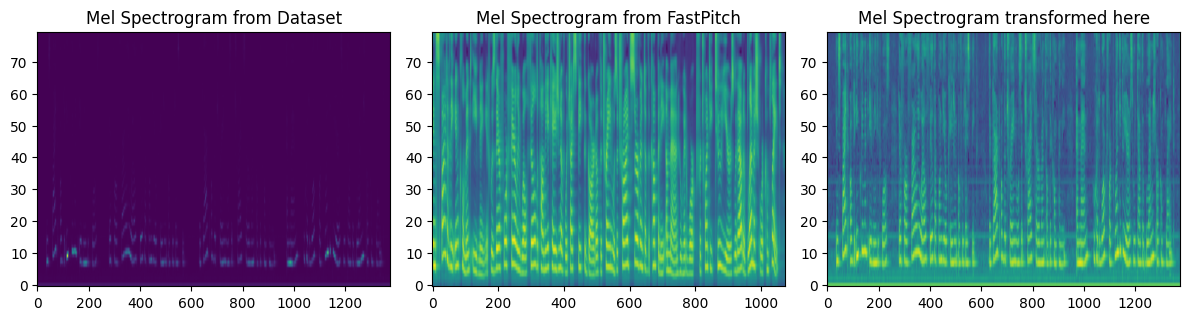

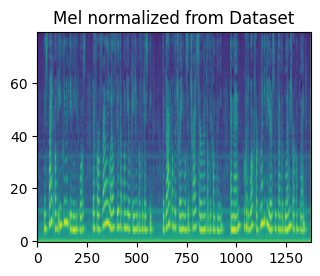

In [9]:
plt.figure(figsize=(12, 6))
plt.subplot(2, 3, 1)
plt.title("Mel Spectrogram from Dataset")
plt.imshow(mel.squeeze().cpu().numpy(), aspect='auto', origin='lower')
plt.subplot(2, 3, 2)
plt.title("Mel Spectrogram from FastPitch")
plt.imshow(mel_from_text.squeeze().cpu().numpy(), aspect='auto', origin='lower')
plt.subplot(2, 3, 3)
plt.title("Mel Spectrogram transformed here")
plt.imshow(mel_db.squeeze().cpu().numpy(), aspect='auto', origin='lower')
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 6))
plt.subplot(2, 3, 1)
plt.title("Mel normalized from Dataset")
plt.imshow(mel_normalized.squeeze().cpu().numpy(), aspect='auto', origin='lower')




As we can see, they are in different spectral spaces. So, we must build a network to convert from one to the other. This is the goal of the next notebook, where we will build a simple feedforward network to learn this mapping. this network will receive the parsed results by spec_generator and the normalized mel spectograms from the dataset and output the mel in the new space. 

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ResConv1DGLU(nn.Module):
    """Bloco Residual com Convolução Dilatada e Gated Linear Unit."""
    def __init__(self, channels, kernel_size=3, dilation=1, dropout=0.1):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.conv = nn.Conv1d(channels, channels * 2, kernel_size, padding=padding, dilation=dilation, bias=False)
        self.norm = nn.InstanceNorm1d(channels, affine=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        res = x
        x = self.conv(x)
        x_tanh, x_sigm = x.chunk(2, dim=1)
        x = torch.tanh(x_tanh) * torch.sigmoid(x_sigm)
        x = self.dropout(self.norm(x))
        return x + res

class TextEncoder(nn.Module):
    """Codifica os tokens de texto para o mesmo espaço latente do Mel."""
    def __init__(self, vocab_size=256, embed_dim=256, hidden_channels=256):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.convs = nn.Sequential(
            nn.Conv1d(embed_dim, hidden_channels, kernel_size=5, padding=2),
            nn.BatchNorm1d(hidden_channels),
            nn.ReLU(),
            nn.Conv1d(hidden_channels, hidden_channels, kernel_size=5, padding=2),
            nn.BatchNorm1d(hidden_channels),
            nn.ReLU()
        )
        
    def forward(self, text_tokens):
        # text_tokens shape: (Batch, L)
        x = self.embedding(text_tokens)     # (Batch, L, Embed_Dim)
        x = x.transpose(1, 2)               # (Batch, Embed_Dim, L)
        x = self.convs(x)                   # (Batch, Hidden_Channels, L)
        return x

class CrossAttentionBlock(nn.Module):
    """Cruza o espectrograma (Query) com o texto (Key/Value)."""
    def __init__(self, d_model, n_heads=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True)
        self.norm = nn.LayerNorm(d_model)
        
    def forward(self, mel_features, text_features):
        # Transforma de (Batch, C, Time) para (Batch, Time, C) exigido pelo Transformer
        mel_q = mel_features.transpose(1, 2)
        text_kv = text_features.transpose(1, 2)
        
        # Cross Attention: O Mel busca informações no Texto
        attn_out, _ = self.attn(query=mel_q, key=text_kv, value=text_kv)
        
        # Conexão residual + LayerNorm
        out = self.norm(mel_q + attn_out)
        
        # Retorna para (Batch, C, Time)
        return out.transpose(1, 2)

class CrossMelTransferNet(nn.Module):
    """
    Rede que recebe o Espectrograma E o Texto (parsed) para gerar o Mel refinado.
    """
    def __init__(self, vocab_size=256, in_channels=80, hidden_channels=256, num_blocks=6):
        super().__init__()
        
        # 1. Encoders Iniciais
        self.text_encoder = TextEncoder(vocab_size, embed_dim=hidden_channels, hidden_channels=hidden_channels)
        
        self.mel_in_layer = nn.Sequential(
            nn.Conv1d(in_channels, hidden_channels, kernel_size=5, padding=2, bias=False),
            nn.InstanceNorm1d(hidden_channels, affine=True),
            nn.LeakyReLU(0.2)
        )
        
        # 2. O Módulo de Cruzamento (Cross-Attention)
        self.cross_attention = CrossAttentionBlock(d_model=hidden_channels, n_heads=4)
        
        # 3. Blocos Residuais Dilatados (Pós-Cruzamento)
        self.blocks = nn.ModuleList()
        for i in range(num_blocks):
            dilation = 2 ** (i % 3) 
            self.blocks.append(ResConv1DGLU(hidden_channels, kernel_size=3, dilation=dilation))
            
        # 4. Projeção de volta para 80 Mels
        self.out_layer = nn.Sequential(
            nn.Conv1d(hidden_channels, hidden_channels, kernel_size=5, padding=2, bias=False),
            nn.LeakyReLU(0.2),
            nn.Conv1d(hidden_channels, in_channels, kernel_size=1)
        )

    def forward(self, mel, text_tokens):
        # mel: (B, 80, T_mel)
        # text_tokens: (B, T_text)
        
        identity = mel 
        
        # Extrai features
        text_feat = self.text_encoder(text_tokens) # (B, 256, T_text)
        mel_feat = self.mel_in_layer(mel)          # (B, 256, T_mel)
        
        # Cruza as informações (Alinha contexto de texto no eixo de tempo do Mel)
        fused_feat = self.cross_attention(mel_features=mel_feat, text_features=text_feat)
        
        # Refinamento de textura acústica
        for block in self.blocks:
            fused_feat = block(fused_feat)
            
        out_mel = self.out_layer(fused_feat)
        
        # Residual global
        return identity + out_mel

In [11]:
from torch.nn.utils.rnn import pad_sequence
import torch

def tts_collate_fn(batch):
    texts = [item["text"] for item in batch]
    
    mels_gt = []
    lengths_gt = []
    
    for item in batch:
        # AQUI: Mudamos para ir buscar o Mel Normalizado do Dataset
        mel = item["mel_normalized"].squeeze() 
        if mel.dim() == 1:
            mel = mel.unsqueeze(0)
            
        # pad_sequence precisa que a dimensão do tempo (T) seja a primeira (T, 80)
        mels_gt.append(mel.transpose(0, 1))
        lengths_gt.append(mel.shape[-1])
        
    # Faz o preenchimento com zeros (Batch, T_max, 80)
    mels_padded = pad_sequence(mels_gt, batch_first=True, padding_value=0.0)
    
    # Retorna para o formato (Batch, 80, T_max)
    mels_padded = mels_padded.transpose(1, 2)
    
    return texts, mels_padded, torch.tensor(lengths_gt, dtype=torch.long)

In [12]:
from torch.nn.utils.rnn import pad_sequence

def train_epoch_cross_batched(model, dataloader, optimizer, device, fastpitch_model):
    model.train()
    fastpitch_model.eval()
    epoch_loss = 0.0
    total_batches = len(dataloader)
    
    for step, (texts, mels_gt, lengths_gt) in enumerate(dataloader):
        mels_gt = mels_gt.to(device)
        lengths_gt = lengths_gt.to(device)
        
        mels_fp_list = []
        tokens_list = []
        
        with torch.no_grad():
            for text in texts:
                # 1. Faz o Parse (extrai os tokens do texto)
                # 'parsed' costuma ter shape (1, L)
                parsed = fastpitch_model.parse(text)
                
                # 2. Gera o Mel
                mel_fp = fastpitch_model.generate_spectrogram(parsed)
                if isinstance(mel_fp, tuple):
                    mel_fp = mel_fp[0]
                    
                mels_fp_list.append(mel_fp.squeeze().transpose(0, 1))
                # Salva os tokens 1D para o pad_sequence
                tokens_list.append(parsed.squeeze())
                
        # Padding dos Mels do FastPitch
        mels_fp_padded = pad_sequence(mels_fp_list, batch_first=True, padding_value=0.0)
        mels_fp_padded = mels_fp_padded.transpose(1, 2).to(device) # (Batch, 80, T_fp_max)
        
        # Padding dos Tokens de Texto
        tokens_padded = pad_sequence(tokens_list, batch_first=True, padding_value=0).to(device) # (Batch, L_max)
        
        optimizer.zero_grad()
        
        # ========================================================
        # AQUI ACONTECE A MÁGICA: Passamos o Mel E O Texto
        # ========================================================
        mels_pred = model(mel=mels_fp_padded, text_tokens=tokens_padded)
        
        # Alinhamento por corte e cálculo da perda mascarada
        min_len = min(mels_pred.shape[-1], mels_gt.shape[-1])
        mels_pred_cropped = mels_pred[:, :, :min_len]
        mels_gt_cropped = mels_gt[:, :, :min_len]
        
        valid_lengths = torch.clamp(lengths_gt, max=min_len)
        mask = torch.arange(min_len, device=device).unsqueeze(0) < valid_lengths.unsqueeze(1)
        mask = mask.unsqueeze(1) 
        
        loss_matrix = F.l1_loss(mels_pred_cropped, mels_gt_cropped, reduction='none')
        loss = (loss_matrix * mask).sum() / mask.sum() 
        
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
        if (step + 1) % 10 == 0 or (step + 1) == total_batches:
            print(f"  Batch {step + 1:03d}/{total_batches} | Cross-Attention L1 Loss: {loss.item():.4f}")
            
    return epoch_loss / total_batches

In [13]:
import torch.nn.functional as F

def train_epoch_batched(model, dataloader, optimizer, device, fastpitch_model):
    model.train()
    fastpitch_model.eval()
    epoch_loss = 0.0
    total_batches = len(dataloader)
    
    for step, (texts, mels_gt, lengths_gt) in enumerate(dataloader):
        mels_gt = mels_gt.to(device)
        lengths_gt = lengths_gt.to(device)
        
        # 1. Gera os Mels do FastPitch para o batch inteiro
        mels_fp_list = []
        with torch.no_grad():
            for text in texts:
                parsed = fastpitch_model.parse(text)
                mel_fp = fastpitch_model.generate_spectrogram(parsed)
                if isinstance(mel_fp, tuple):
                    mel_fp = mel_fp[0]
                # Prepara para padding (T, 80)
                mels_fp_list.append(mel_fp.squeeze().transpose(0, 1))
                
        # 2. Faz o padding dos Mels gerados pelo FastPitch
        mels_fp_padded = pad_sequence(mels_fp_list, batch_first=True, padding_value=0.0)
        mels_fp_padded = mels_fp_padded.transpose(1, 2).to(device) # (Batch, 80, T_fp_max)
        
        optimizer.zero_grad()
        
        # 3. Passa TODO o batch pela rede
        mels_pred = model(mels_fp_padded)
        
        # 4. Alinhamento por corte (truncamento pelo menor tempo real do batch)
        min_len = min(mels_pred.shape[-1], mels_gt.shape[-1])
        mels_pred_cropped = mels_pred[:, :, :min_len]
        mels_gt_cropped = mels_gt[:, :, :min_len]
        
        # 5. Máscara de comprimentos reais (Ignorar o padding na hora da Loss)
        # valid_lengths garante que não ultrapassemos o min_len após o corte
        valid_lengths = torch.clamp(lengths_gt, max=min_len)
        
        # Cria uma máscara booleana de tamanho (Batch, 1, min_len)
        mask = torch.arange(min_len, device=device).unsqueeze(0) < valid_lengths.unsqueeze(1)
        mask = mask.unsqueeze(1) # Expande para multiplicar com os 80 canais
        
        # 6. Cálculo da Perda L1 Mascarada
        # Calculamos erro absoluto de tudo, mas zeramos os frames de padding
        loss_matrix = F.l1_loss(mels_pred_cropped, mels_gt_cropped, reduction='none')
        loss = (loss_matrix * mask).sum() / mask.sum() # Média apenas sobre os dados reais!
        
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
        if (step + 1) % 10 == 0 or (step + 1) == total_batches:
            print(f"  Batch {step + 1:03d}/{total_batches} | Masked L1 Loss: {loss.item():.4f}")
            
    return epoch_loss / total_batches

In [ ]:
from torch.utils.data import DataLoader
from torch.optim import AdamW

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instancia a NOVA arquitetura (CrossMelTransferNet)
transfer_net = CrossMelTransferNet(vocab_size=512, in_channels=80, hidden_channels=256, num_blocks=6)
transfer_net = transfer_net.to(device)
fastpitch_mel = fastpitch_mel.to(device)

In [ ]:


optimizer = AdamW(transfer_net.parameters(), lr=1e-4, weight_decay=1e-5)

BATCH_SIZE = 128

dataloader = DataLoader(
    data_set,                 
    batch_size=BATCH_SIZE,
    shuffle=True,             
    collate_fn=tts_collate_fn, # (Use a mesma collate_fn fornecida anteriormente)
    num_workers=4,            
    pin_memory=True           
)

epochs = 15 # Redes com atenção podem exigir um pouco mais de épocas para alinhar

print(f"Iniciando treinamento no device: {device} | Batches por época: {len(dataloader)}")

for epoch in range(epochs):
    print(f"\n--- Epoch {epoch + 1}/{epochs} ---")
    
    loss_epoch = train_epoch_cross_batched(
        model=transfer_net,
        dataloader=dataloader,
        optimizer=optimizer,
        device=device,
        fastpitch_model=fastpitch_mel
    )
    
    print(f"Epoch {epoch + 1} finalizada | Avg Masked L1 Loss: {loss_epoch:.4f}")
    
    if (epoch + 1) % 2 == 0:
        checkpoint_path = f"cross_mel_transfer_epoch_{epoch + 1}.pt"
        torch.save(transfer_net.state_dict(), checkpoint_path)
        print(f"Checkpoint salvo: {checkpoint_path}")
        
print("Treinamento batched com Cross-Attention concluído!")

Iniciando treinamento no device: cuda | Batches por época: 1162

--- Epoch 1/15 ---
  Batch 010/1162 | Cross-Attention L1 Loss: 71.7405
  Batch 020/1162 | Cross-Attention L1 Loss: 65.9453
  Batch 030/1162 | Cross-Attention L1 Loss: 63.3111
  Batch 040/1162 | Cross-Attention L1 Loss: 63.0534
  Batch 050/1162 | Cross-Attention L1 Loss: 63.2584
  Batch 060/1162 | Cross-Attention L1 Loss: 62.9077
  Batch 070/1162 | Cross-Attention L1 Loss: 63.9735
  Batch 080/1162 | Cross-Attention L1 Loss: 67.2505
  Batch 090/1162 | Cross-Attention L1 Loss: 65.5962
  Batch 100/1162 | Cross-Attention L1 Loss: 63.3202
  Batch 110/1162 | Cross-Attention L1 Loss: 64.5644
  Batch 120/1162 | Cross-Attention L1 Loss: 62.0256
  Batch 130/1162 | Cross-Attention L1 Loss: 66.8744
  Batch 140/1162 | Cross-Attention L1 Loss: 65.7787
  Batch 150/1162 | Cross-Attention L1 Loss: 63.5497
  Batch 160/1162 | Cross-Attention L1 Loss: 63.8585
  Batch 170/1162 | Cross-Attention L1 Loss: 64.3339
  Batch 180/1162 | Cross-Attenti

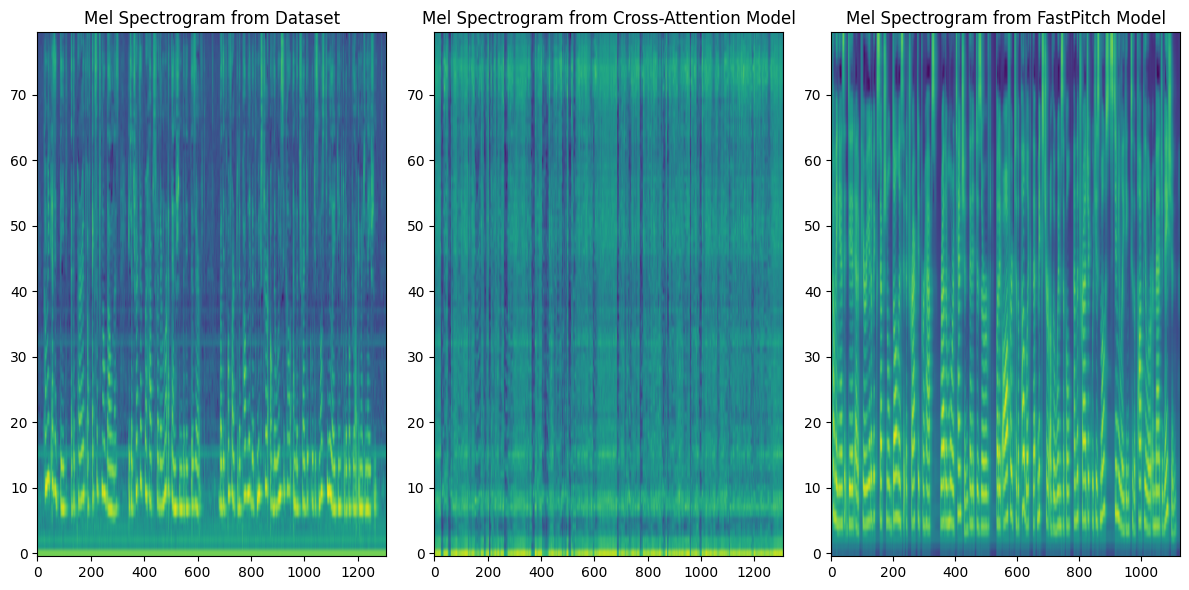

<module 'matplotlib.pyplot' from '/home/richard/project/ml2_final_project/.venv/lib/python3.12/site-packages/matplotlib/pyplot.py'>

In [22]:
text_test, mel_test = data_set[0]["text"], data_set[0]["mel"]

mel_model = transfer_net(mel_test.to(device), fastpitch_mel.parse(text_test).to(device))

parsed = fastpitch_mel.parse(text_test)
mel_from_text = fastpitch_mel.generate_spectrogram(parsed)

mel_test, mel_model, mel_from_text = mel_test.squeeze().cpu().detach().numpy(), mel_model.squeeze().cpu().detach().numpy(), mel_from_text.squeeze().cpu().detach().numpy()

plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.title("Mel Spectrogram from Dataset")
plt.imshow(mel_test, aspect='auto', origin='lower')
plt.subplot(1, 3, 2)
plt.title("Mel Spectrogram from Cross-Attention Model")
plt.imshow(mel_model, aspect='auto', origin='lower')
plt.subplot(1, 3, 3)
plt.title("Mel Spectrogram from FastPitch Model")
plt.imshow(mel_from_text, aspect='auto', origin='lower')
plt.tight_layout()
plt.show()
plt



In [10]:
vocoder.eval()

with torch.no_grad():
    device = vocoder.device

    # 1. Dataset Mel -> Clean shapes to exactly [Mel_Channels, Time] -> Add Batch -> To GPU
    # This guarantees the shape is exactly [1, 80, Time] regardless of how it started
    mel_db_cleaned = mel_db.squeeze().unsqueeze(0).to(device)
    audio_dataset_tensor = vocoder.convert_spectrogram_to_audio(spec=mel_db_cleaned).squeeze()
    audio_generated_from_mel_dataset = audio_dataset_tensor.cpu().numpy()

    # 2. FastPitch Mel -> Clean shapes to exactly [Mel_Channels, Time] -> Add Batch -> To GPU
    mel_from_text_cleaned = mel_from_text.squeeze().unsqueeze(0).to(device)
    audio_fastpitch_tensor = vocoder.convert_spectrogram_to_audio(spec=mel_from_text_cleaned).squeeze()
    audio_generated_from_mel_fastpitch = audio_fastpitch_tensor.cpu().numpy()

    mel_from_dataset = mel.squeeze().unsqueeze(0).to(device)
    audio_from_dataset_dataset = vocoder.convert_spectrogram_to_audio(spec=mel_from_dataset).squeeze()
    audio_from_mel_dataset = audio_from_dataset_dataset.cpu().numpy()

    mel_normalized_from_dataset = mel_normalized.squeeze().unsqueeze(0).to(device)
    audio_from_dataset_normalized = vocoder.convert_spectrogram_to_audio(spec=mel_normalized_from_dataset).squeeze()
    audio_from_dataset_normalized = audio_from_dataset_normalized.cpu().numpy()

    # 3. Ground Truth Audio -> To CPU -> NumPy
    if isinstance(audio_waveform, torch.Tensor):
        audio_original = audio_waveform.squeeze().cpu().numpy()
    else:
        audio_original = audio_waveform.squeeze()

# --- Render all 3 players cleanly ---
print("🔊 Audio from Dataset Mel:")
display(Audio(audio_generated_from_mel_dataset, rate=22050))

print("🔊 Audio from FastPitch Mel:")
display(Audio(audio_generated_from_mel_fastpitch, rate=22050))

print("🔊 Audio from Dataset Mel transformed here:")
display(Audio(audio_from_mel_dataset, rate=22050))

print("🔊 Audio from Dataset Mel Normalized transformed here:")
display(Audio(audio_from_dataset_normalized, rate=22050))

print("🔊 Original Ground Truth Audio:")
display(Audio(audio_original, rate=22050))


🔊 Audio from Dataset Mel:


🔊 Audio from FastPitch Mel:


🔊 Audio from Dataset Mel transformed here:


🔊 Audio from Dataset Mel Normalized transformed here:


🔊 Original Ground Truth Audio:
